# NOTEBOOK FOR PART II OF THE FIRST COURSEWORK

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 2.1. K-Nearest Neighbors

### 2.1.1. Generating the data

First, we code the functions to be used in this section. These are the random training dataset generator and the K-NN algorithm.

In [69]:
def generate_random_h(n=100):
    X = np.random.uniform(low=0, high=1, size=(n, 2))
    y = np.random.choice([0,1], size=n)
    # np.hstack((X,y[:, None])),
    return X, y

def euclidean_distance(x1, x2):
    return np.linalg.norm(x1-x2, axis=1) # this computes the distance between x2 and each of the rows of x1
    
def knn_classifier(X, y, X_test, v=3):
    y_pred = []
    for data_test in X_test:
        distances = euclidean_distance(X, data_test)
        neighbors_index = np.argsort(distances)[:v]
        neighbors_class = y[neighbors_index]
        if np.mean(neighbors_class) > 0.5:
            y_pred.append(1)
        elif np.mean(neighbors_class) < 0.5:
            y_pred.append(0)
        else: 
            # equal amount of 0 and 1 neighbors
            y_pred.append(np.random.choice([0,1]))
    return np.array(y_pred)

#### 6. Produce a visualisation of $h_{S,v}$ similar to the figure.

We start by generating a grid which covers the space $[0,1]^2$, and the random training dataset. We will run the K-NN algorithm with K=3 over all the points in the grid.

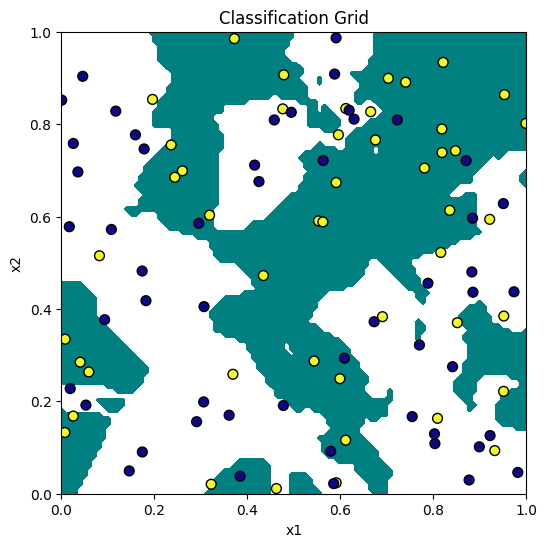

In [ ]:
# generate grid
x1 = np.linspace(0,1,100)
x2 = np.linspace(0,1,100)
gridX1, gridX2 = np.meshgrid(x1,x2)
grid = np.column_stack([gridX1.ravel(), gridX2.ravel()])

# generate train dataset
X, y = generate_random_h()

# run K-NN
y_pred = knn_classifier(X, y, grid)

# generate plot
plt.figure(figsize=(6,6))
plt.contourf(gridX1, gridX2, y_pred.reshape(100,100), levels=[-0.1, 0.5, 1.1], colors=['teal','white'])
plt.scatter(X[:,0], X[:,1], c=y, cmap='plasma', edgecolor='k', s=50, label='Points')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Classification Grid')
plt.show()



### 2.1.2. Estimated generalization error of k-NN as a function of k.

#### 7.a) Produce a visualisation using Protocol A (see Figure 2).

In [82]:
def ph_y(X):
    y_train = []
    for x in X:
        if np.random.uniform(low=0, high=1) < 0.8:
            # in this case, y = h(x)
            y_train.append(knn_classifier(X_prob, y_prob, x[None])[0])
        else:
            # in this casem y uniformly sampled from {0,1}
            y_train.append(np.random.choice([0,1], size=1)[0])
    return np.array(y_train)

gen_error = []
for k in range(1, 50):
    errors_k = []
    for _ in range(100):
        X_prob, y_prob = generate_random_h()
        X_train = np.random.uniform(low=0, high=1, size=(4000,2))
        y_train = ph_y(X_train)
        X_test = np.random.uniform(low=0, high=1, size=(1000,2))
        y_test = ph_y(X_test)
        y_pred = knn_classifier(X_train, y_train, X_test, v=k)
        errors_k.append(sum(y_pred != y_test))
    gen_error.append(np.mean(errors_k))

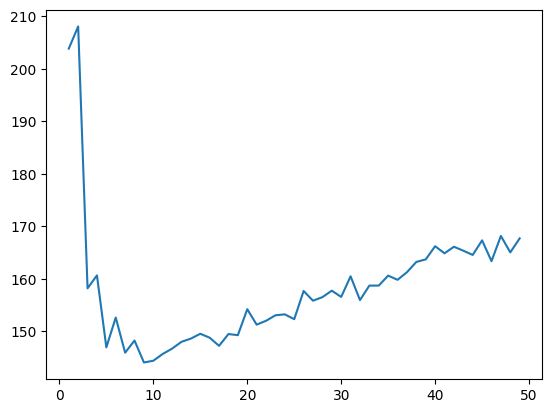

In [86]:
x = range(1, 50)
plt.plot(x, gen_error)

#### 7.b) Using roughly 5 sentences explain why the figure is the approximate shape that it is and comment on any interesting features of the figure.

### 8. Determine the optimal k as a function of the number of training points (m).

#### 8.a) Produce a visualisation using Protocol B (see Figure 3). I.e, plotting m versus optimal k.

In [92]:
optimal_km = []
for m in [100, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000]:
    for _ in range(100):
        optimal_k = []
        errors = []
        for k in range(1, 50):
            X_prob, y_prob = generate_random_h()
            X_train = np.random.uniform(low=0, high=1, size=(m,2))
            y_train = ph_y(X_train)
            X_test = np.random.uniform(low=0, high=1, size=(1000,2))
            y_test = ph_y(X_test)
            y_pred = knn_classifier(X_train, y_train, X_test, v=k)
            errors.append(sum(y_pred != y_test))
        optimal_k.append(np.argmin(np.array(errors)) + 1)
    optimal_km.append(np.mean(optimal_k))

KeyboardInterrupt: 

#### 8.b) Using roughly 4 sentences explain why the figure is the approximate shape that it is.